# Projeto Integrado — Telemetria de Jogos
### Parte 3 — Processamento com Apache Spark
**Equipe 4 | Big Data**

Seguindo o padrão da Aula 9, as **sessões de jogo** chegam em lotes (como se os jogadores estivessem jogando agora) e o Spark as processa de forma contínua. A telemetria real de um jogo é um fluxo de eventos, o que representa a **velocidade** (um dos 5 Vs do Big Data).

**Como os dados chegam aqui:** um processo em segundo plano lê o arquivo `sessoes_limpo.csv` (camada tratada do Data Lake), em ordem de data, e grava lotes de sessões em arquivos JSON na pasta de entrada. O Spark acompanha essa pasta e processa cada lote assim que ele aparece.

**Relação com a arquitetura do projeto**

| Componente | Papel | Neste notebook |
|---|---|---|
| HDFS | Armazena os CSVs tratados em `/telemetria/limpos/` | Aqui lemos do Google Drive; em um cluster bastaria trocar o caminho |
| YARN | Gerencia os recursos da execução | Aqui o Spark roda em modo local; no cluster usaria `--master yarn` |
| Hive | Consulta SQL sobre os dados | O Spark SQL faz o papel equivalente sobre tabelas temporárias |
| Spark | Processamento em memória | Todo o notebook |

In [1]:
# Apache Spark precisa ser instalado dessa forma, pois não existe nativamente
# (nem com import padrão)
%pip -q install pyspark matplotlib pandas seaborn

In [2]:
# Bibliotecas utilizadas para organizar as pastas, gravar os arquivos e coletar dados
import json
import os

# Ferramentas extras de manipulação de arquivos e pastas
import shutil

# Execução de eventos em segundo plano
import threading

# Controle de tempo entre as coletas
import time

# Análise de dados e geração de gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [3]:
# Componentes do Apache Spark
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType

## Conhecendo os dados do projeto

`sessoes_limpo.csv` -> sessões de jogo (jogador, plataforma, gênero do jogo, duração e níveis)

`jogadores_limpo.csv`, `partidas_limpo.csv`, `compras_limpo.csv`, `itens_compras_limpo.csv`, `itens_limpo.csv` -> demais tabelas, carregadas mais adiante

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Pasta do Google Drive onde estão os CSVs tratados pelo ETL
# Ajuste o caminho se necessário
PASTA = '/content/drive/MyDrive/PI_telemetria_de_jogos/'

# Lê as sessões e coloca em ordem cronológica (como se chegassem em tempo real)
dados = pd.read_csv(PASTA + 'sessoes_limpo.csv').sort_values('data_inicio_sessao').reset_index(drop=True)

# Exibir
print("Sessões encontradas: ", len(dados))
print("Exemplo de registro: ")
print(json.dumps(dados.iloc[0].to_dict(), indent=2, default=str, ensure_ascii=False))

Sessões encontradas:  37366
Exemplo de registro: 
{
  "sessao_id": 24075,
  "player_id": 634,
  "data_inicio_sessao": "2010-04-01 15:38:15",
  "data_fim_sessao": "2010-04-01 17:08:15",
  "duracao_minutos": 90,
  "plataforma": "Xbox",
  "genero_jogo": "Esportes",
  "nivel_inicio": 1,
  "nivel_fim": 1
}


## Criando a sessão Spark

Mecanismo para processamento de dados contínuos

In [6]:
# Criação da sessão Spark
# Se a sessão já estiver criada, ele só pega ela, senão, ele cria pela primeira vez
spark = SparkSession.builder.appName("Projeto_Telemetria_Jogos").getOrCreate()

# Reduzir as mensagens técnicas
spark.sparkContext.setLogLevel("ERROR")

print("Spark iniciado. Versão: ", spark.version)

Spark iniciado. Versão:  4.0.5


## Preparar as pastas do streaming
### Streaming = carregamento contínuo dos dados

- **entrada**: contém os arquivos JSON que o Spark deverá processar;

- **temporarios**: recebe o arquivo durante a gravação. Depois de pronto, vai para a pasta 'entrada';

- **checkpoint**: guarda informações sobre o processamento do Spark

In [7]:
# Pasta principal da atividade no Google Colab.
PASTA_BASE = "/content/telemetria_stream"
PASTA_ENTRADA = f"{PASTA_BASE}/entrada"
PASTA_TEMPORARIOS = f"{PASTA_BASE}/temporarios"
PASTA_CHECKPOINT = f"{PASTA_BASE}/checkpoint"

# Limpa apenas os arquivos de uma execução anterior da atividade.
shutil.rmtree(PASTA_BASE, ignore_errors=True)

# Cria as pastas necessárias para a nova execução.
os.makedirs(PASTA_ENTRADA, exist_ok=True)
os.makedirs(PASTA_TEMPORARIOS, exist_ok=True)

print("Pasta acompanhada pelo Spark:", PASTA_ENTRADA)

Pasta acompanhada pelo Spark: /content/telemetria_stream/entrada


## Definindo os campos que o Spark vai ler

In [8]:
# Definindo o formato dos dados do JSON
esquema = StructType([
    StructField('coleta', IntegerType()),
    StructField('sessao_id', IntegerType()),
    StructField('player_id', IntegerType()),
    StructField('instante', StringType()),
    StructField('plataforma', StringType()),
    StructField('genero_jogo', StringType()),
    StructField('duracao_minutos', IntegerType()),
    StructField('nivel_inicio', IntegerType()),
    StructField('nivel_fim', IntegerType()),
])

# Configura a leitura contínua dos novos arquivos JSON
df_stream = spark.readStream.schema(esquema).json(PASTA_ENTRADA)

## Transformando os dados recebidos

Criamos duas colunas novas:

- **situacao** (duração da sessão): Curta (até 60 min), Média (60 a 120 min) ou Longa (mais de 120 min)

- **ganho_nivel**: quantos níveis o jogador subiu na sessão

In [9]:
# Criando coluna de classificação
sessoes_stream = (
    df_stream
    .withColumn(
        "situacao",
        F.when(F.col("duracao_minutos") <= 60, "Curta")
        .when(F.col("duracao_minutos") <= 120, "Média")
        .otherwise("Longa")
    )
    .withColumn("ganho_nivel", F.col("nivel_fim") - F.col("nivel_inicio"))
)

sessoes_stream.printSchema()

root
 |-- coleta: integer (nullable = true)
 |-- sessao_id: integer (nullable = true)
 |-- player_id: integer (nullable = true)
 |-- instante: string (nullable = true)
 |-- plataforma: string (nullable = true)
 |-- genero_jogo: string (nullable = true)
 |-- duracao_minutos: integer (nullable = true)
 |-- nivel_inicio: integer (nullable = true)
 |-- nivel_fim: integer (nullable = true)
 |-- situacao: string (nullable = false)
 |-- ganho_nivel: integer (nullable = true)



## Iniciando o Spark Structured Streaming

In [10]:
# Iniciando o processamento contínuo com os dados da pasta entrada
# O resultado fica guardado em memória, na tabela "sessoes_stream"
consulta = (
    sessoes_stream.writeStream
    .format("memory")
    .queryName("sessoes_stream")
    .outputMode("append")
    .option("checkpointLocation", PASTA_CHECKPOINT)
    .trigger(processingTime="5 seconds")
    .start()
)

print(consulta.isActive)

True


## Criando a coleta automática em segundo plano

1. Pegar o próximo lote de sessões

2. Criar um arquivo JSON com os dados

3. Mover o arquivo para a pasta de entrada (o Spark processa)

4. Esperar alguns segundos para repetir

In [11]:
TAMANHO_LOTE = 2000       # sessões enviadas a cada coleta
INTERVALO_SEGUNDOS = 5    # tempo entre as coletas

parar_coleta = threading.Event()
coleta_concluida = threading.Event()
numero_coleta = 0
posicao = 0               # indica até onde os dados já foram enviados

def coletar():
    global numero_coleta, posicao

    # Seleciona o próximo lote de sessões.
    lote = dados.iloc[posicao: posicao + TAMANHO_LOTE]

    # Registra o número do novo lote.
    proxima_coleta = numero_coleta + 1

    # Prepara um arquivo JSON: cada linha representa uma sessão.
    arquivo_nome = f"coleta_{proxima_coleta:05d}.json"
    caminho_temporario = os.path.join(PASTA_TEMPORARIOS, arquivo_nome)
    caminho_final = os.path.join(PASTA_ENTRADA, arquivo_nome)

    with open(caminho_temporario, "w", encoding="utf-8") as arquivo:
        for _, linha in lote.iterrows():
            registro = {
                "coleta": proxima_coleta,
                "sessao_id": int(linha["sessao_id"]),
                "player_id": int(linha["player_id"]),
                "instante": str(linha["data_inicio_sessao"]),
                "plataforma": linha["plataforma"],
                "genero_jogo": linha["genero_jogo"],
                "duracao_minutos": int(linha["duracao_minutos"]),
                "nivel_inicio": int(linha["nivel_inicio"]),
                "nivel_fim": int(linha["nivel_fim"])
            }
            arquivo.write(json.dumps(registro, ensure_ascii=False) + "\n")

    # Move o arquivo pronto para a pasta acompanhada pelo Spark.
    os.replace(caminho_temporario, caminho_final)
    numero_coleta = proxima_coleta
    posicao += len(lote)
    print(f"Coleta {numero_coleta}: {len(lote)} sessões enviadas ({posicao}/{len(dados)})")


def executar_coleta_automatica():
    # Enquanto não houver pedido de parada e ainda houver dados, envia um lote por intervalo.
    while not parar_coleta.is_set() and posicao < len(dados):
        try:
            coletar()
        except (ValueError, OSError, KeyError) as erro:
            # Uma falha temporária não encerra a tarefa.
            print("Falha na coleta:", erro)

        # Espera o intervalo definido, mas permite interromper imediatamente.
        if parar_coleta.wait(INTERVALO_SEGUNDOS):
            break

    coleta_concluida.set()
    print("Coleta finalizada.")

In [12]:
# Iniciando a coleta automática uma vez
if "tarefa_coleta" not in globals() or not tarefa_coleta.is_alive():
    parar_coleta.clear()
    tarefa_coleta = threading.Thread(target=executar_coleta_automatica, daemon=True)
    tarefa_coleta.start()

print("Coleta ativa em 2 plano? ", tarefa_coleta.is_alive())

Coleta ativa em 2 plano?  True


## Consultar os dados
#### Execute a célula abaixo quantas vezes quiser enquanto a coleta acontece: os números crescem a cada lote.

In [13]:
def mostrar_resultados():
    # Obtém a coleta mais recente que já foi processada pelo Spark.
    ultima_coleta = spark.sql("SELECT MAX(coleta) AS numero FROM sessoes_stream").first()["numero"]

    if ultima_coleta is None:
        print("Ainda não há dados processados. Execute esta célula novamente em alguns segundos.")
        return

    # Seleciona todas as sessões processadas até agora.
    acumulado = spark.sql("SELECT * FROM sessoes_stream")

    # Calcula os indicadores considerando tudo o que já foi processado.
    resumo = acumulado.agg(

        # Conta o número total de sessões recebidas.
        F.count("*").alias("Sessoes"),

        # Conta quantos jogadores diferentes já jogaram.
        F.countDistinct("player_id").alias("Jogadores ativos"),

        # Soma o tempo jogado e converte de minutos para horas.
        F.round(F.sum("duracao_minutos") / 60, 0).alias("Horas jogadas"),

        # Calcula a duração média das sessões.
        F.round(F.avg("duracao_minutos"), 1).alias("Duracao media (min)"),

        # Conta quantas sessões foram longas (mais de 120 minutos).
        # F.when(..., 1) retorna 1 quando a condição é verdadeira, senão 0.
        # F.sum() soma esses valores, contando as sessões longas.
        F.sum(
            F.when(F.col("situacao") == "Longa", 1).otherwise(0)
        ).alias("Sessoes longas")

    )

    print(f"RESULTADOS ATÉ A COLETA {ultima_coleta}")
    display(resumo.toPandas())

    # Mostra quantas sessões estão em cada situação (duração).
    contagem = (acumulado.groupBy("situacao").count().toPandas()
                .set_index("situacao").reindex(["Curta", "Média", "Longa"]).reset_index())
    contagem.plot.bar(x="situacao", y="count", legend=False, figsize=(7, 3))
    plt.title("Sessões por duração")
    plt.xlabel("")
    plt.ylabel("Quantidade de sessões")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Exibe os dez gêneros de jogo com mais sessões.
    top = acumulado.groupBy("genero_jogo").count().orderBy(F.desc("count")).limit(10).toPandas()
    top.sort_values("count").plot.barh(
        x="genero_jogo", y="count", legend=False, figsize=(8, 4)
    )
    plt.title("Gêneros de jogo com mais sessões")
    plt.xlabel("Sessões")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

In [14]:
mostrar_resultados()

Coleta 1: 2000 sessões enviadas (2000/37366)
Ainda não há dados processados. Execute esta célula novamente em alguns segundos.


In [15]:
# Agrupa os registros por coleta para comparar diferentes instantes.
evolucao = spark.sql("""
    SELECT coleta,
           COUNT(*) AS sessoes,
           SUM(COUNT(*)) OVER (ORDER BY coleta) AS sessoes_acumuladas,
           ROUND(AVG(duracao_minutos), 1) AS duracao_media
    FROM sessoes_stream
    GROUP BY coleta
    ORDER BY coleta
""")

# Transforma apenas o resumo (poucas linhas) em Pandas para criar o gráfico.
tabela_evolucao = evolucao.toPandas()
display(tabela_evolucao)

if len(tabela_evolucao) >= 2:
    tabela_evolucao.plot(
        x="coleta", y=["sessoes", "sessoes_acumuladas"], marker="o", figsize=(8, 4)
    )
    plt.title("Evolução das sessões processadas a cada coleta")
    plt.xlabel("Número da coleta")
    plt.ylabel("Quantidade")
    plt.tight_layout()
    plt.show()
else:
    print("Aguarde ao menos duas coletas para comparar os resultados.")

Coleta 2: 2000 sessões enviadas (4000/37366)


,coleta,sessoes,sessoes_acumuladas,duracao_media


Aguarde ao menos duas coletas para comparar os resultados.


## Aguardando o fim da coleta
Antes da análise completa, esperamos todos os lotes serem enviados e processados pelo Spark.

In [16]:
# Espera a tarefa de coleta terminar de enviar os arquivos
while tarefa_coleta.is_alive():
    time.sleep(2)

# Espera o Spark processar tudo o que já chegou na pasta de entrada
consulta.processAllAvailable()

total_processado = spark.sql("SELECT COUNT(*) AS n FROM sessoes_stream").first()["n"]
print(f"Sessões processadas pelo Spark: {total_processado} de {len(dados)}")

Coleta 3: 2000 sessões enviadas (6000/37366)
Coleta 4: 2000 sessões enviadas (8000/37366)
Coleta 5: 2000 sessões enviadas (10000/37366)
Coleta 6: 2000 sessões enviadas (12000/37366)
Coleta 7: 2000 sessões enviadas (14000/37366)
Coleta 8: 2000 sessões enviadas (16000/37366)
Coleta 9: 2000 sessões enviadas (18000/37366)
Coleta 10: 2000 sessões enviadas (20000/37366)
Coleta 11: 2000 sessões enviadas (22000/37366)
Coleta 12: 2000 sessões enviadas (24000/37366)
Coleta 13: 2000 sessões enviadas (26000/37366)
Coleta 14: 2000 sessões enviadas (28000/37366)
Coleta 15: 2000 sessões enviadas (30000/37366)
Coleta 16: 2000 sessões enviadas (32000/37366)
Coleta 17: 2000 sessões enviadas (34000/37366)
Coleta 18: 2000 sessões enviadas (36000/37366)
Coleta 19: 1366 sessões enviadas (37366/37366)
Coleta finalizada.
Sessões processadas pelo Spark: 37366 de 37366


## Carregando as demais tabelas do projeto
Jogadores, partidas, compras e itens não mudam durante o fluxo, então são lidos como DataFrames comuns (dados estáticos) e registrados como tabelas temporárias para o Spark SQL.

In [17]:
def ler(nome):
    return spark.read.csv(PASTA + nome, header=True, inferSchema=True)

jogadores     = ler('jogadores_limpo.csv')
partidas      = ler('partidas_limpo.csv')
compras       = ler('compras_limpo.csv')
itens_compras = ler('itens_compras_limpo.csv')
itens         = ler('itens_limpo.csv')

jogadores.createOrReplaceTempView('jogadores')
partidas.createOrReplaceTempView('partidas')
compras.createOrReplaceTempView('compras')
itens_compras.createOrReplaceTempView('itens_compras')
itens.createOrReplaceTempView('itens')

pd.DataFrame({
    'Tabela': ['sessoes_stream', 'jogadores', 'partidas', 'compras', 'itens_compras', 'itens'],
    'Registros': [total_processado, jogadores.count(), partidas.count(), compras.count(),
                  itens_compras.count(), itens.count()]
})

,Tabela,Registros
0,sessoes_stream,37366
1,jogadores,1000
2,partidas,58312
3,compras,1425
4,itens_compras,1963
5,itens,37


## Trabalhando com DataFrames
Seleção, filtro, ordenação e criação de colunas sobre a tabela que o streaming construiu.

In [18]:
# A tabela em memória do streaming vira um DataFrame comum
sessoes = spark.table("sessoes_stream")

# Cria colunas derivadas: data, ano, mês e horas
sessoes = (sessoes
    .withColumn("data_inicio", F.to_timestamp("instante"))
    .withColumn("ano", F.year("data_inicio"))
    .withColumn("mes", F.month("data_inicio"))
    .withColumn("horas", F.col("duracao_minutos") / 60))

sessoes.createOrReplaceTempView("sessoes")

# SELECT + FILTER + ORDER BY: as 10 sessões mais longas jogadas no PC
(sessoes
    .select("sessao_id", "player_id", "plataforma", "genero_jogo", "duracao_minutos")
    .filter(F.col("plataforma") == "PC")
    .orderBy(F.col("duracao_minutos").desc())
    .show(10))

+---------+---------+----------+-----------+---------------+
|sessao_id|player_id|plataforma|genero_jogo|duracao_minutos|
+---------+---------+----------+-----------+---------------+
|    10062|      262|        PC|   Survival|            270|
|    15310|      400|        PC|   Survival|            270|
|    35685|      959|        PC|   Survival|            270|
|    15181|      395|        PC|   Survival|            270|
|    20917|      550|        PC|   Survival|            270|
|    23220|      612|        PC|   Survival|            269|
|    31380|      834|        PC|   Survival|            269|
|    26880|      702|        PC|   Survival|            269|
|    29969|      791|        PC|   Survival|            268|
|    24718|      645|        PC|   Survival|            268|
+---------+---------+----------+-----------+---------------+
only showing top 10 rows


## Transformações e agrupamentos
`groupBy` + `agg` calculam várias métricas de uma vez.

In [19]:
# Engajamento por plataforma
por_plataforma = (sessoes.groupBy("plataforma")
    .agg(F.count("sessao_id").alias("sessoes"),
         F.countDistinct("player_id").alias("jogadores_ativos"),
         F.round(F.avg("duracao_minutos"), 1).alias("duracao_media_min"),
         F.round(F.sum("horas"), 0).alias("horas_jogadas"))
    .orderBy(F.col("horas_jogadas").desc()))
por_plataforma.show()

+-----------+-------+----------------+-----------------+-------------+
| plataforma|sessoes|jogadores_ativos|duracao_media_min|horas_jogadas|
+-----------+-------+----------------+-----------------+-------------+
|         PC|  15355|             689|            101.8|      26064.0|
|       Xbox|  10686|             419|             97.1|      17298.0|
|PlayStation|   9979|             396|            100.4|      16694.0|
|     Mobile|   1346|             222|             89.6|       2011.0|
+-----------+-------+----------------+-----------------+-------------+



In [20]:
# Engajamento por gênero de jogo
por_genero = (sessoes.groupBy("genero_jogo")
    .agg(F.count("sessao_id").alias("sessoes"),
         F.round(F.avg("duracao_minutos"), 1).alias("duracao_media_min"),
         F.round(F.avg("ganho_nivel"), 2).alias("ganho_nivel_medio"))
    .orderBy(F.col("sessoes").desc()))
por_genero.show()

+-----------+-------+-----------------+-----------------+
|genero_jogo|sessoes|duracao_media_min|ganho_nivel_medio|
+-----------+-------+-----------------+-----------------+
|        FPS|   4516|             69.7|             1.16|
| Estratégia|   3836|            110.2|             1.35|
|   Esportes|   3565|             70.2|             1.33|
|    Corrida|   3409|             59.6|             1.39|
|       Ação|   3397|             90.0|             1.28|
|       Luta|   3225|             52.6|             1.33|
|   Survival|   3202|            166.5|             1.38|
|   Aventura|   3168|            110.7|             1.34|
|       MOBA|   3043|             88.7|             1.39|
|  Simulação|   3040|            151.1|             1.37|
|        RPG|   2965|            150.1|             1.34|
+-----------+-------+-----------------+-----------------+



In [21]:
# JOIN: sessões + jogadores -> top 10 países por horas jogadas
(sessoes.join(jogadores, on="player_id", how="left")
    .groupBy("pais")
    .agg(F.countDistinct("player_id").alias("jogadores"),
         F.round(F.sum("horas"), 0).alias("horas_jogadas"))
    .orderBy(F.col("horas_jogadas").desc())
    .show(10))

+--------------+---------+-------------+
|          pais|jogadores|horas_jogadas|
+--------------+---------+-------------+
|Estados Unidos|      189|      12857.0|
|        Itália|      130|       7790.0|
|        França|      112|       7223.0|
|        México|      110|       6496.0|
|       Espanha|       92|       5934.0|
|      Alemanha|       98|       5207.0|
|        Brasil|       79|       4721.0|
|   Reino Unido|       69|       4352.0|
|     Austrália|       55|       3443.0|
|        Canadá|       34|       1878.0|
+--------------+---------+-------------+
only showing top 10 rows


## Consultas com Spark SQL
Usamos SQL padrão sobre as tabelas temporárias (equivalente ao que faríamos no Hive).

In [22]:
# Consulta 1: sessões por plataforma e gênero (cruzamento de duas dimensões)
spark.sql("""
    SELECT plataforma, genero_jogo,
           COUNT(*)                        AS sessoes,
           ROUND(AVG(duracao_minutos), 1)  AS duracao_media
    FROM sessoes
    GROUP BY plataforma, genero_jogo
    ORDER BY sessoes DESC
    LIMIT 10
""").show()

+-----------+-----------+-------+-------------+
| plataforma|genero_jogo|sessoes|duracao_media|
+-----------+-----------+-------+-------------+
|         PC| Estratégia|   3836|        110.2|
|         PC|       MOBA|   1697|         87.9|
|         PC|        FPS|   1616|         68.9|
|       Xbox|        FPS|   1456|         69.8|
|PlayStation|        FPS|   1444|         70.5|
|       Xbox|   Esportes|   1356|         69.7|
|PlayStation|   Esportes|   1348|         69.4|
|     Mobile|       MOBA|   1346|         89.6|
|       Xbox|       Luta|   1326|         53.3|
|       Xbox|    Corrida|   1271|         60.4|
+-----------+-----------+-------+-------------+



In [23]:
# Consulta 2: gênero mais jogado em cada plataforma (função de janela)
spark.sql("""
    SELECT plataforma, genero_jogo, sessoes FROM (
        SELECT plataforma, genero_jogo, COUNT(*) AS sessoes,
               ROW_NUMBER() OVER (PARTITION BY plataforma ORDER BY COUNT(*) DESC) AS posicao
        FROM sessoes
        GROUP BY plataforma, genero_jogo
    ) WHERE posicao = 1
    ORDER BY sessoes DESC
""").show()

+-----------+-----------+-------+
| plataforma|genero_jogo|sessoes|
+-----------+-----------+-------+
|         PC| Estratégia|   3836|
|       Xbox|        FPS|   1456|
|PlayStation|        FPS|   1444|
|     Mobile|       MOBA|   1346|
+-----------+-----------+-------+



In [24]:
# Consulta 3: receita por plataforma (compras ligadas às sessões do streaming)
spark.sql("""
    SELECT s.plataforma,
           COUNT(DISTINCT c.compra_id)         AS compras,
           ROUND(SUM(ic.valor_total_item), 2)  AS receita
    FROM compras c
    JOIN itens_compras ic ON ic.compra_id = c.compra_id
    JOIN sessoes s        ON s.sessao_id  = c.sessao_id
    GROUP BY s.plataforma
    ORDER BY receita DESC
""").show()

+-----------+-------+--------+
| plataforma|compras| receita|
+-----------+-------+--------+
|         PC|    594|17625.52|
|       Xbox|    414| 12867.7|
|PlayStation|    373|10898.55|
|     Mobile|     44| 1362.02|
+-----------+-------+--------+



In [25]:
# Consulta 4: 10 itens que mais geram receita
spark.sql("""
    SELECT i.nome_item, i.categoria_item, i.raridade,
           SUM(ic.quantidade)                 AS unidades,
           ROUND(SUM(ic.valor_total_item), 2) AS receita
    FROM itens_compras ic
    JOIN itens i ON ic.item_id = i.item_id
    GROUP BY i.nome_item, i.categoria_item, i.raridade
    ORDER BY receita DESC
    LIMIT 10
""").show(truncate=False)

+--------------------+--------------+--------+--------+-------+
|nome_item           |categoria_item|raridade|unidades|receita|
+--------------------+--------------+--------+--------+-------+
|Pintura Especial    |Cosmético     |Épica   |63      |3063.85|
|2500 Moedas         |Moeda virtual |Épica   |76      |2952.57|
|100 Moedas          |Moeda virtual |Lendária|60      |2896.66|
|Personagem Guerreiro|Personagem    |Lendária|42      |2437.93|
|Boost de XP         |Boost         |Épica   |75      |2206.6 |
|Personagem Caçador  |Personagem    |Épica   |52      |2024.89|
|Skin Sombria        |Skin          |Épica   |66      |1936.02|
|Expansão Final      |DLC           |Épica   |62      |1805.97|
|Boost de Progressão |Boost         |Rara    |62      |1795.49|
|Expansão Norte      |DLC           |Rara    |56      |1620.56|
+--------------------+--------------+--------+--------+-------+



## Indicadores (KPIs)

In [26]:
# Gasto por jogador: itens_compras -> compras -> sessoes (player_id)
compras_jogador = compras.join(sessoes.select("sessao_id", "player_id"), on="sessao_id", how="left")
gasto_jogador = (itens_compras.join(compras_jogador.select("compra_id", "player_id"), on="compra_id")
                 .groupBy("player_id").agg(F.sum("valor_total_item").alias("gasto_total")))

total_jogadores = jogadores.count()
jogadores_ativos = sessoes.select("player_id").distinct().count()
total_sessoes = sessoes.count()
horas_jogadas = sessoes.agg(F.sum("horas")).first()[0]
duracao_media = sessoes.agg(F.avg("duracao_minutos")).first()[0]
total_partidas = partidas.count()
taxa_vitoria = (partidas.filter(F.col("resultado").isNotNull())
                .agg(F.avg((F.col("resultado") == "Vitória").cast("int"))).first()[0])
receita_total = itens_compras.agg(F.sum("valor_total_item")).first()[0]
n_compras = compras.count()
pagantes = gasto_jogador.count()

kpis = pd.DataFrame({
    "Indicador": ["Jogadores cadastrados", "Jogadores ativos (com sessão)", "Sessões", "Horas jogadas",
                  "Duração média da sessão (min)", "Partidas", "Taxa de vitória", "Receita total",
                  "Compras", "Ticket médio por compra", "Jogadores pagantes", "% de pagantes",
                  "Receita média por pagante"],
    "Valor": [f"{total_jogadores:,}", f"{jogadores_ativos:,}", f"{total_sessoes:,}", f"{horas_jogadas:,.0f}",
              f"{duracao_media:.1f}", f"{total_partidas:,}", f"{taxa_vitoria:.1%}", f"{receita_total:,.2f}",
              f"{n_compras:,}", f"{receita_total / n_compras:,.2f}", f"{pagantes:,}",
              f"{pagantes / total_jogadores:.1%}", f"{receita_total / pagantes:,.2f}"]
})
kpis

,Indicador,Valor
0,Jogadores cadastrados,"1,000"
1,Jogadores ativos (com sessão),"1,000"
2,Sessões,"37,366"
3,Horas jogadas,"62,067"
4,Duração média da sessão (min),99.7
5,Partidas,"58,312"
6,Taxa de vitória,46.9%
7,Receita total,"42,753.79"
8,Compras,"1,425"
9,Ticket médio por compra,30.00


## Gráficos e interpretações
Os dados já agregados pelo Spark (poucas linhas) são convertidos para Pandas apenas para desenhar os gráficos. As frases de interpretação são geradas a partir dos resultados.

### Comparação — horas jogadas por plataforma

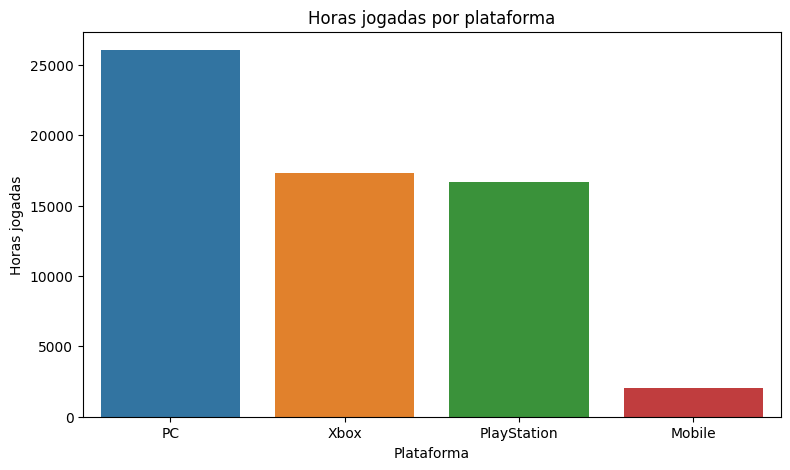

Interpretação: PC concentra mais horas (26,064 h, 42.0% do total). A menor é Mobile (3.2%).


In [27]:
pdf = por_plataforma.toPandas()

plt.figure(figsize=(9, 5))
sns.barplot(data=pdf, x="plataforma", y="horas_jogadas", hue="plataforma", legend=False)
plt.title("Horas jogadas por plataforma")
plt.xlabel("Plataforma"); plt.ylabel("Horas jogadas")
plt.show()

top = pdf.iloc[0]
print(f"Interpretação: {top.plataforma} concentra mais horas ({top.horas_jogadas:,.0f} h, "
      f"{top.horas_jogadas / pdf.horas_jogadas.sum():.1%} do total). "
      f"A menor é {pdf.iloc[-1].plataforma} ({pdf.iloc[-1].horas_jogadas / pdf.horas_jogadas.sum():.1%}).")

**Contribuição para a decisão:** mostra onde está o público mais engajado e indica em qual plataforma priorizar lançamentos, correções e eventos.

### Comparação — duração média da sessão por gênero

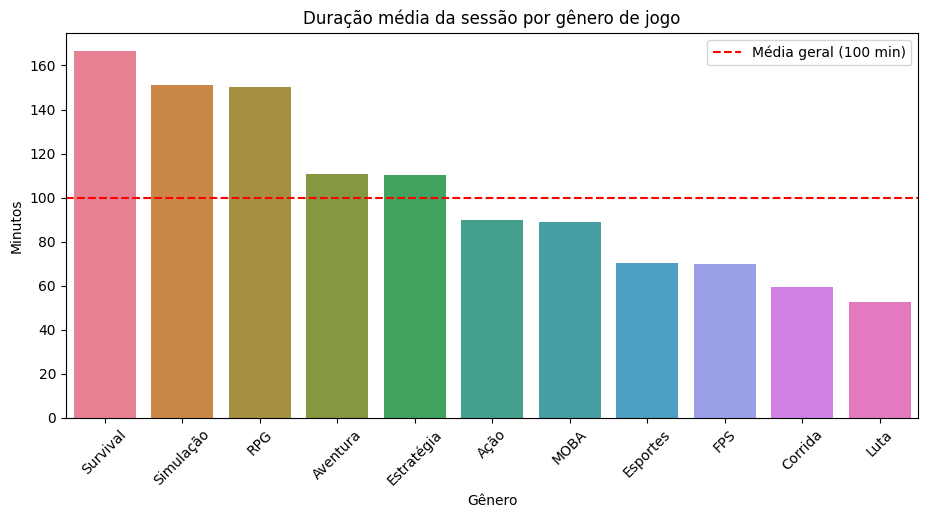

Interpretação: sessões de Survival são as mais longas (166 min) e as de Luta as mais curtas (53 min). A diferença entre extremos é de 114 min.


In [28]:
pdf = por_genero.toPandas().sort_values("duracao_media_min", ascending=False)

plt.figure(figsize=(11, 5))
sns.barplot(data=pdf, x="genero_jogo", y="duracao_media_min", hue="genero_jogo", legend=False)
plt.axhline(duracao_media, color="red", linestyle="--", label=f"Média geral ({duracao_media:.0f} min)")
plt.xticks(rotation=45); plt.legend()
plt.title("Duração média da sessão por gênero de jogo")
plt.xlabel("Gênero"); plt.ylabel("Minutos")
plt.show()

a, b = pdf.iloc[0], pdf.iloc[-1]
print(f"Interpretação: sessões de {a.genero_jogo} são as mais longas ({a.duracao_media_min:.0f} min) e as de "
      f"{b.genero_jogo} as mais curtas ({b.duracao_media_min:.0f} min). A diferença entre extremos é de "
      f"{a.duracao_media_min - b.duracao_media_min:.0f} min.")

**Contribuição para a decisão:** gêneros com sessões longas favorecem monetização ligada a tempo de jogo (passe de batalha, boosts); gêneros de sessão curta combinam com compras rápidas.

### Variação temporal — sessões por ano

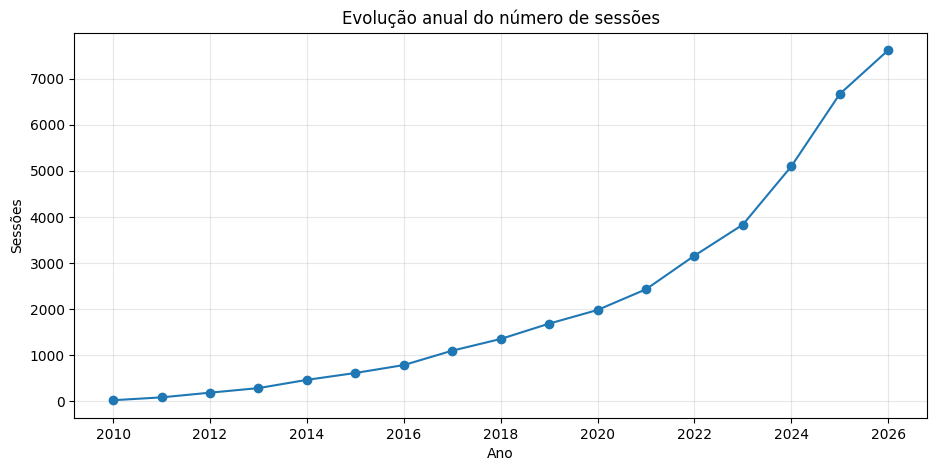

Interpretação: o maior volume de sessões ocorreu em 2026 (7,618 sessões). O primeiro ano registrado é 2010 e o último é 2026.
Observação: o último ano pode estar incompleto, então uma queda nele pode refletir só o período coberto pelos dados.


In [29]:
por_ano = (sessoes.groupBy("ano").agg(F.count("*").alias("sessoes"),
                                      F.round(F.sum("horas"), 0).alias("horas"))
           .orderBy("ano").toPandas())

plt.figure(figsize=(11, 5))
plt.plot(por_ano.ano, por_ano.sessoes, marker="o")
plt.title("Evolução anual do número de sessões")
plt.xlabel("Ano"); plt.ylabel("Sessões"); plt.grid(alpha=0.3)
plt.show()

pico = por_ano.loc[por_ano.sessoes.idxmax()]
print(f"Interpretação: o maior volume de sessões ocorreu em {int(pico.ano)} ({int(pico.sessoes):,} sessões). "
      f"O primeiro ano registrado é {int(por_ano.ano.min())} e o último é {int(por_ano.ano.max())}.")
print("Observação: o último ano pode estar incompleto, então uma queda nele pode refletir só o período coberto pelos dados.")

**Contribuição para a decisão:** a tendência mostra se a base de jogadores está crescendo, estável ou perdendo engajamento ao longo do tempo.

### Distribuição — duração das sessões

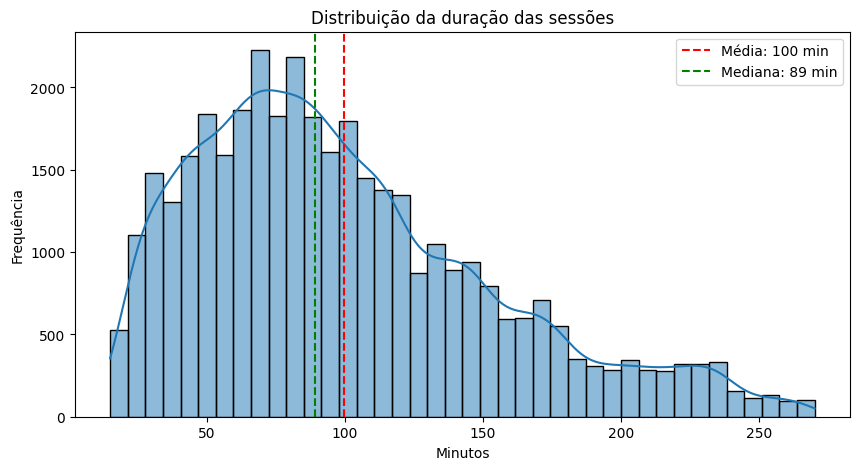

Interpretação: a mediana é 89 min e a média 100 min. A média acima da mediana indica cauda à direita (poucas sessões muito longas). A maioria das sessões (50% centrais) está entre 59 e 131 min.


In [30]:
dur = sessoes.select("duracao_minutos").toPandas()["duracao_minutos"]

plt.figure(figsize=(10, 5))
sns.histplot(dur, bins=40, kde=True)
plt.axvline(dur.mean(), color="red", linestyle="--", label=f"Média: {dur.mean():.0f} min")
plt.axvline(dur.median(), color="green", linestyle="--", label=f"Mediana: {dur.median():.0f} min")
plt.legend(); plt.title("Distribuição da duração das sessões")
plt.xlabel("Minutos"); plt.ylabel("Frequência")
plt.show()

print(f"Interpretação: a mediana é {dur.median():.0f} min e a média {dur.mean():.0f} min. "
      f"{'A média acima da mediana indica cauda à direita (poucas sessões muito longas).' if dur.mean() > dur.median() else 'Média e mediana próximas indicam distribuição equilibrada.'} "
      f"A maioria das sessões (50% centrais) está entre {dur.quantile(.25):.0f} e {dur.quantile(.75):.0f} min.")

**Contribuição para a decisão:** a duração típica de sessão orienta o desenho de conteúdo (partidas, missões e eventos) para caber no tempo que o jogador realmente joga.

### Valores discrepantes (outliers) — duração por plataforma

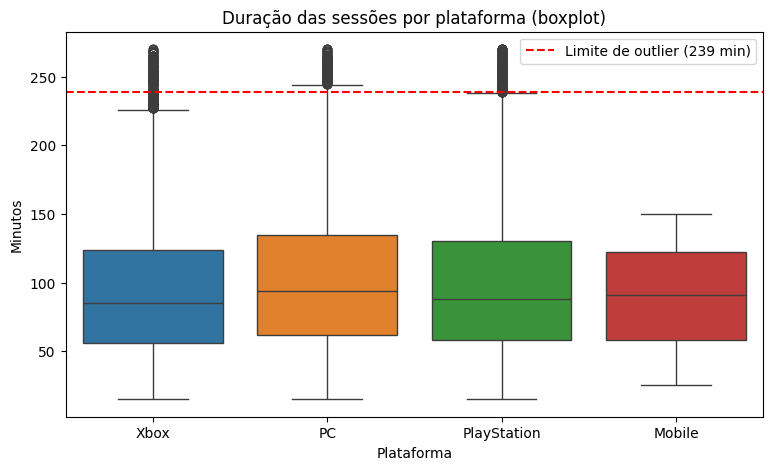

Interpretação: pelo critério do IQR, sessões acima de 239 min são outliers: 550 sessões (1.47% do total). Maior sessão: 270 min.


In [31]:
q1, q3 = sessoes.approxQuantile("duracao_minutos", [0.25, 0.75], 0.001)
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
n_out = sessoes.filter(F.col("duracao_minutos") > limite_sup).count()

box = sessoes.select("plataforma", "duracao_minutos").toPandas()
plt.figure(figsize=(9, 5))
sns.boxplot(data=box, x="plataforma", y="duracao_minutos", hue="plataforma", legend=False)
plt.axhline(limite_sup, color="red", linestyle="--", label=f"Limite de outlier ({limite_sup:.0f} min)")
plt.legend(); plt.title("Duração das sessões por plataforma (boxplot)")
plt.xlabel("Plataforma"); plt.ylabel("Minutos")
plt.show()

print(f"Interpretação: pelo critério do IQR, sessões acima de {limite_sup:.0f} min são outliers: "
      f"{n_out:,} sessões ({n_out / total_sessoes:.2%} do total). Maior sessão: {box.duracao_minutos.max()} min.")

**Contribuição para a decisão:** sessões muito longas podem ser jogadores muito engajados (público a fidelizar) ou sessões esquecidas abertas (erro de telemetria). Vale investigá-las antes de usar a média em relatórios.

### Correlação — variáveis das sessões e dos jogadores

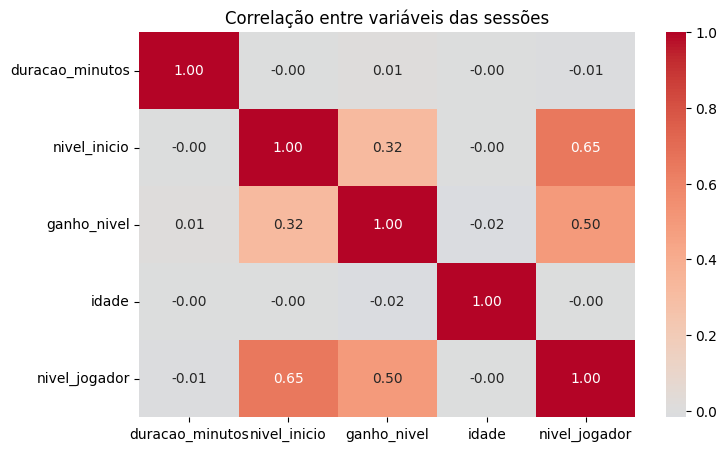

Interpretação: a correlação mais forte é entre 'nivel_inicio' e 'nivel_jogador' (r = 0.65). A duração da sessão tem correlação de 0.01 com o ganho de nível.


In [32]:
corr_df = (sessoes.join(jogadores.select("player_id", "idade", "nivel_jogador"), on="player_id", how="left")
           .select("duracao_minutos", "nivel_inicio", "ganho_nivel", "idade", "nivel_jogador")
           .toPandas())
corr = corr_df.corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre variáveis das sessões")
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)
(v1, v2), r = pares.index[0], pares.iloc[0]
print(f"Interpretação: a correlação mais forte é entre '{v1}' e '{v2}' (r = {r:.2f}). "
      f"A duração da sessão tem correlação de {corr.loc['duracao_minutos', 'ganho_nivel']:.2f} com o ganho de nível.")

**Contribuição para a decisão:** correlações óbvias (como nível do jogador e nível inicial da sessão) confirmam a consistência dos dados. Correlações fracas entre idade, duração e ganho de nível indicam que o perfil demográfico, sozinho, explica pouco do comportamento, o que justifica a clusterização na Parte 4.

### Receita por categoria de item

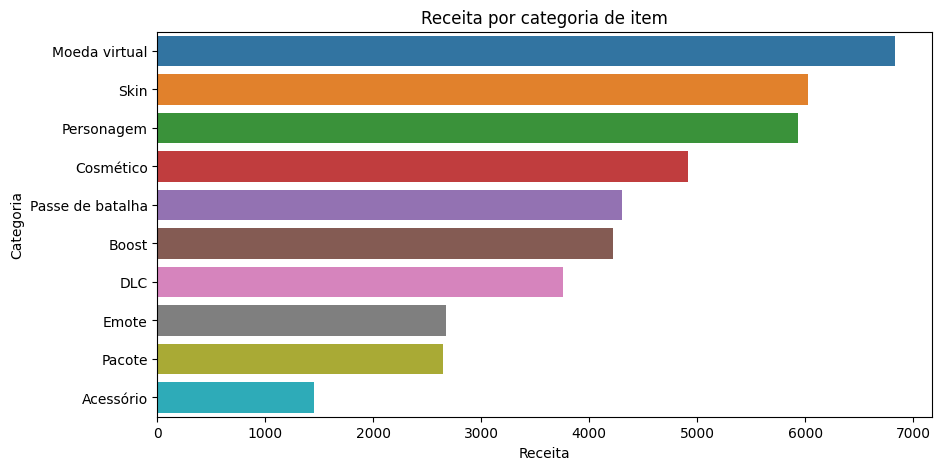

Interpretação: Moeda virtual é a categoria que mais fatura (6,836.07, 16.0% da receita). As 3 maiores somam 44.0%.


In [33]:
receita_categoria = (itens_compras.join(itens, on="item_id", how="left")
    .groupBy("categoria_item")
    .agg(F.round(F.sum("valor_total_item"), 2).alias("receita"))
    .orderBy(F.col("receita").desc())
    .toPandas())

plt.figure(figsize=(10, 5))
sns.barplot(data=receita_categoria, x="receita", y="categoria_item", hue="categoria_item", legend=False)
plt.title("Receita por categoria de item")
plt.xlabel("Receita"); plt.ylabel("Categoria")
plt.show()

t = receita_categoria.iloc[0]
print(f"Interpretação: {t.categoria_item} é a categoria que mais fatura ({t.receita:,.2f}, "
      f"{t.receita / receita_categoria.receita.sum():.1%} da receita). "
      f"As 3 maiores somam {receita_categoria.receita.head(3).sum() / receita_categoria.receita.sum():.1%}.")

**Contribuição para a decisão:** mostra onde concentrar o catálogo e as promoções, e quais categorias têm pouca contribuição.

### Resultado das partidas

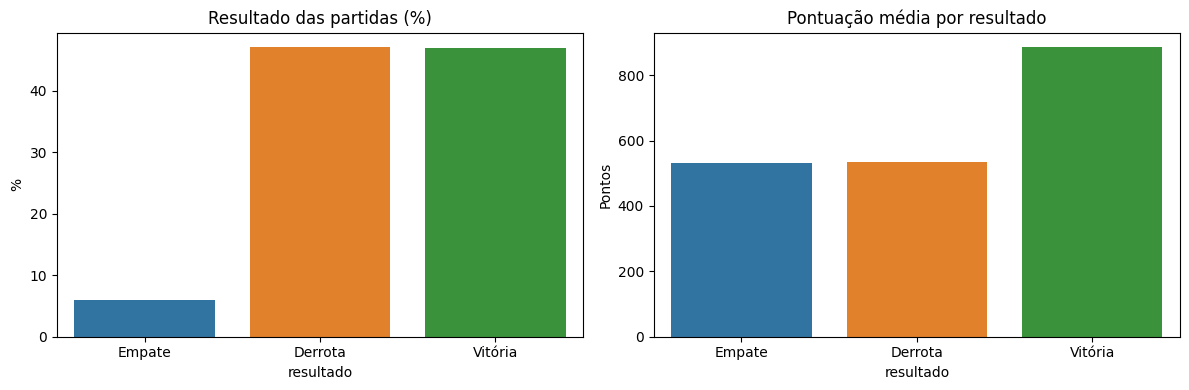

Interpretação: vitórias representam 46.9% das partidas. Partidas vencidas rendem pontuação média de 885, contra 534 nas derrotas.


In [34]:
res = (partidas.filter(F.col("resultado").isNotNull()).groupBy("resultado")
       .agg(F.count("*").alias("partidas"), F.round(F.avg("pontuacao"), 0).alias("pontuacao_media"))
       .toPandas())
res["percentual"] = 100 * res.partidas / res.partidas.sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=res, x="resultado", y="percentual", hue="resultado", legend=False, ax=ax[0])
ax[0].set_title("Resultado das partidas (%)"); ax[0].set_ylabel("%")
sns.barplot(data=res, x="resultado", y="pontuacao_media", hue="resultado", legend=False, ax=ax[1])
ax[1].set_title("Pontuação média por resultado"); ax[1].set_ylabel("Pontos")
plt.tight_layout(); plt.show()

v = res.set_index("resultado")
print(f"Interpretação: vitórias representam {v.loc['Vitória','percentual']:.1f}% das partidas. "
      f"Partidas vencidas rendem pontuação média de {v.loc['Vitória','pontuacao_media']:.0f}, "
      f"contra {v.loc['Derrota','pontuacao_media']:.0f} nas derrotas.")

**Contribuição para a decisão:** o equilíbrio entre vitórias e derrotas indica se o *matchmaking* é justo. A pontuação mais alta nas vitórias confirma que ela reflete o desempenho.

## Encerrando o processamento

In [35]:
# Solicita a parada do coletor de dados
parar_coleta.set()

# Aguarda o término da tarefa Python antes de encerrar o Spark
tarefa_coleta.join(timeout=35)

# Para a leitura contínua e libera os recursos computacionais
consulta.stop()
spark.stop()

print("Coleta em segundo plano ativa? ", tarefa_coleta.is_alive())
print("Structured Streaming ativo? ", consulta.isActive)

Coleta em segundo plano ativa?  False
Structured Streaming ativo?  False


## Conclusão
- O Spark Structured Streaming recebeu a telemetria em lotes e a processou continuamente, o que representa a característica de **velocidade** do Big Data.
- Com DataFrames e Spark SQL, foram feitos seleção, filtros, ordenação, agrupamentos e junções entre o fluxo e as tabelas estáticas do projeto.
- Os indicadores resumem engajamento, desempenho e receita; os gráficos cobrem comparação, tendência temporal, distribuição, outliers, correlação e receita, cada um com interpretação.
- Em um cluster Hadoop, o mesmo código leria os arquivos do HDFS e rodaria sobre o YARN, trocando apenas os caminhos e o parâmetro `master`.